Task 3.2

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pymc as pm
import pytensor.tensor as pt

In [2]:
# 1) Параметры
np.random.seed(42)

R = 2.0
N = 40
r = 0.1
a = 0.5
Y = 10000
lambda_zat = 8.0

E_true = 2.718
pos_true = np.array([0.27, 0.10, 0.26])

In [3]:
# 2) Положения ФЭУ
i = np.arange(N)
z_fmt = -R + 2 * R * (i + 0.5) / N
r_ring = np.sqrt(R**2 - z_fmt**2)
phi = i * np.pi / np.e

x_fmt = r_ring * np.cos(phi)
y_fmt = r_ring * np.sin(phi)
fmt_positions = np.column_stack([x_fmt, y_fmt, z_fmt])

In [4]:
# 3) Ожидаемый заряд на ФЭУ
def get_mu(pos, E):
    d = fmt_positions - pos
    L = np.sqrt(np.sum(d**2, axis=1))
    c = np.sum(d * fmt_positions, axis=1) / (L * R)

    p_geom = r**2 * c / (4 * L**2)
    p_zat = np.exp(-L / lambda_zat)
    return E * Y * a * p_geom * p_zat

In [5]:
# 4) Генерация наблюдаемого отклика
mu_true = get_mu(pos_true, E_true)
Q_obs = np.random.poisson(mu_true)

print(f"Суммарный заряд: {np.sum(Q_obs)}")
print(f"Ожидалось: {np.sum(mu_true):.1f}")
print(f"Минимальный заряд: {np.min(Q_obs)}")
print(f"Максимальный заряд: {np.max(Q_obs)}")

Суммарный заряд: 264
Ожидалось: 266.1
Минимальный заряд: 2
Максимальный заряд: 16


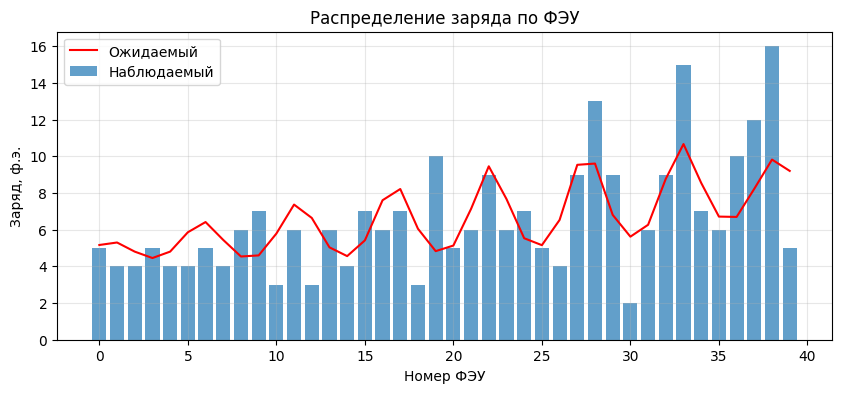

In [6]:
# 5) Наблюдаемый заряд
plt.figure(figsize=(10, 4))
plt.bar(i, Q_obs, alpha=0.7, label='Наблюдаемый')
plt.plot(i, mu_true, 'r-', label='Ожидаемый')
plt.xlabel('Номер ФЭУ')
plt.ylabel('Заряд, ф.э.')
plt.title('Распределение заряда по ФЭУ')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [7]:
# 6) Байесовская модель
with pm.Model() as model:
    E = pm.Uniform('E', lower=0.01, upper=10.0)
    x = pm.Uniform('x', lower=-1.0, upper=1.0)
    y = pm.Uniform('y', lower=-1.0, upper=1.0)
    z = pm.Uniform('z', lower=-1.0, upper=1.0)

    pos = pt.stack([x, y, z])
    d = fmt_positions - pos
    L = pt.sqrt(pt.sum(d**2, axis=1))
    c = pt.sum(d * fmt_positions, axis=1) / (L * R)

    p_geom = r**2 * c / (4 * L**2)
    p_zat = pt.exp(-L / lambda_zat)
    mu = E * Y * a * p_geom * p_zat

    Q = pm.Poisson('Q', mu=mu, observed=Q_obs)

In [8]:
# 7) Сэмплирование
with model:
    trace = pm.sample(draws=2500, tune=1000, chains=4, cores=1,
                      target_accept=0.9, random_seed=42, progressbar=False)

Initializing NUTS using jitter+adapt_diag...
Sequential sampling (4 chains in 1 job)
NUTS: [E, x, y, z]
Sampling 4 chains for 1_000 tune and 2_500 draw iterations (4_000 + 10_000 draws total) took 4 seconds.


In [9]:
# 8) Реконструкция параметров
E_vals = trace.posterior['E'].values.flatten()
x_vals = trace.posterior['x'].values.flatten()
y_vals = trace.posterior['y'].values.flatten()
z_vals = trace.posterior['z'].values.flatten()

E_mean = np.mean(E_vals)
E_std = np.std(E_vals)
pos_mean = np.array([np.mean(x_vals), np.mean(y_vals), np.mean(z_vals)])
pos_std = np.array([np.std(x_vals), np.std(y_vals), np.std(z_vals)])

d_pos = np.linalg.norm(pos_mean - pos_true)
sigma_pos = np.linalg.norm(pos_std)

In [10]:
# 9) Результаты реконструкции
print(f"E: {E_true:.3f} -> {E_mean:.3f} ± {E_std:.3f} МэВ")
for j, name in enumerate(['x', 'y', 'z']):
    print(f"{name}: {pos_true[j]:.3f} -> {pos_mean[j]:.3f} ± {pos_std[j]:.3f} м")

print(f"Ошибка положения: {d_pos:.3f} м")
print(f"Неопределённость положения: {sigma_pos:.3f} м")

E: 2.718 -> 2.698 ± 0.166 МэВ
x: 0.270 -> 0.238 ± 0.093 м
y: 0.100 -> 0.065 ± 0.089 м
z: 0.260 -> 0.427 ± 0.089 м
Ошибка положения: 0.174 м
Неопределённость положения: 0.156 м


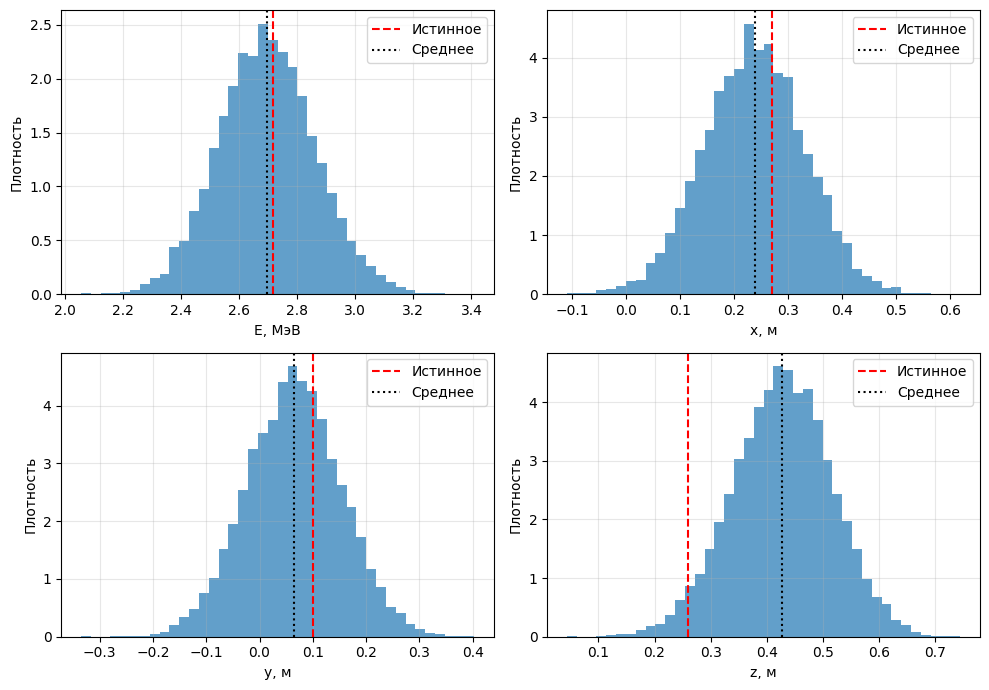

In [11]:
# 10) Апостериорные распределения
vals = [E_vals, x_vals, y_vals, z_vals]
true_vals = [E_true, *pos_true]
names = ['E, МэВ', 'x, м', 'y, м', 'z, м']

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for ax, v, v_true, name in zip(axes.flat, vals, true_vals, names):
    ax.hist(v, bins=40, density=True, alpha=0.7)
    ax.axvline(v_true, color='red', linestyle='--', label='Истинное')
    ax.axvline(np.mean(v), color='black', linestyle=':', label='Среднее')
    ax.set_xlabel(name)
    ax.set_ylabel('Плотность')
    ax.grid(True, alpha=0.3)
    ax.legend()

plt.tight_layout()
plt.show()

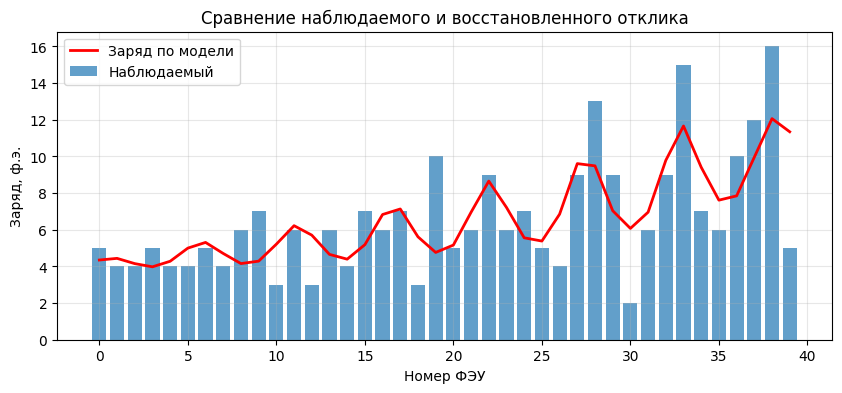

In [12]:
# 11) Сравнение отклика
mu_fit = get_mu(pos_mean, E_mean)
i = np.arange(N)

plt.figure(figsize=(10, 4))
plt.bar(i, Q_obs, alpha=0.7, label='Наблюдаемый')
plt.plot(i, mu_fit, 'r-', linewidth=2, label='Заряд по модели')
plt.xlabel('Номер ФЭУ')
plt.ylabel('Заряд, ф.э.')
plt.title('Сравнение наблюдаемого и восстановленного отклика')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

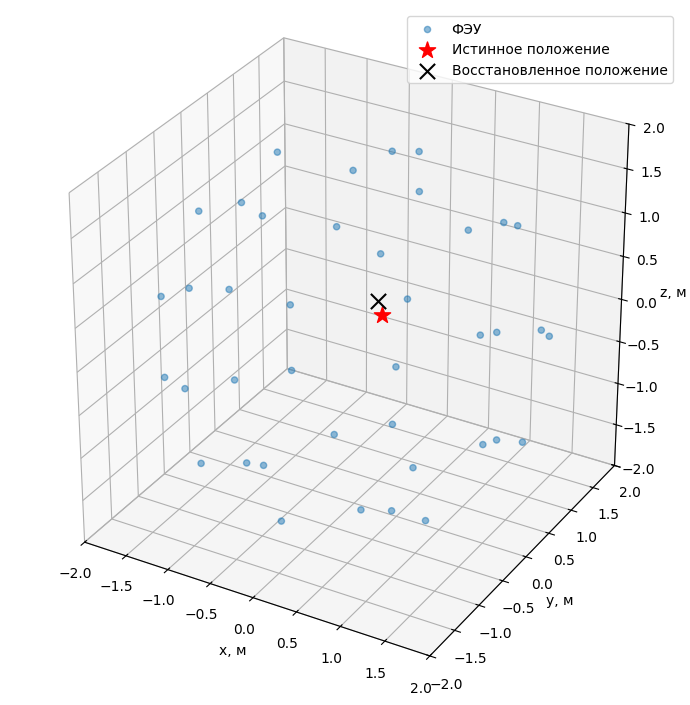

In [13]:
# 12) Положение события
fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(*fmt_positions.T, s=20, alpha=0.5, label='ФЭУ')
ax.scatter(*pos_true, s=150, marker='*', color='red', label='Истинное положение')
ax.scatter(*pos_mean, s=120, marker='x', color='black', label='Восстановленное положение')
ax.set_xlabel('x, м')
ax.set_ylabel('y, м')
ax.set_zlabel('z, м')
ax.set(xlim=(-R, R), ylim=(-R, R), zlim=(-R, R))
ax.set_box_aspect((1, 1, 1))
ax.legend()
plt.tight_layout()
plt.show()